# 13 · What a scalar trace discards

Two fields rotate their director in opposite senses along a ring. They have equal scalar correlations at all lags. The directed matrix correlations reveal the difference at the same spatial sampling and lag range.

In [3]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.core import power, bispectrum
from observables.patterns import homometric
from observables.stage3 import (tile_library, render, tile_q, cyclic_statistics, matrix_profile,
                                crop_census, orbit, FAMILIES, CONDITIONS, METHODS, run)
OUT = ROOT/'results'/'stage3'
OUT.mkdir(exist_ok=True, parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
a, b = homometric()

For a two-channel local nematic field $v_i=(\Re m_{2,i},\Im m_{2,i})$, define
$M(r)=N^{-1}\sum_i v_i v_{i+r}^\top$. Its trace sums the same-channel correlations. The antisymmetric projection $M_{12}-M_{21}$ is another scalar at each lag. It measures the mean signed area spanned by the two channel vectors. Its sign requires a common handed coordinate frame and a directed lag.

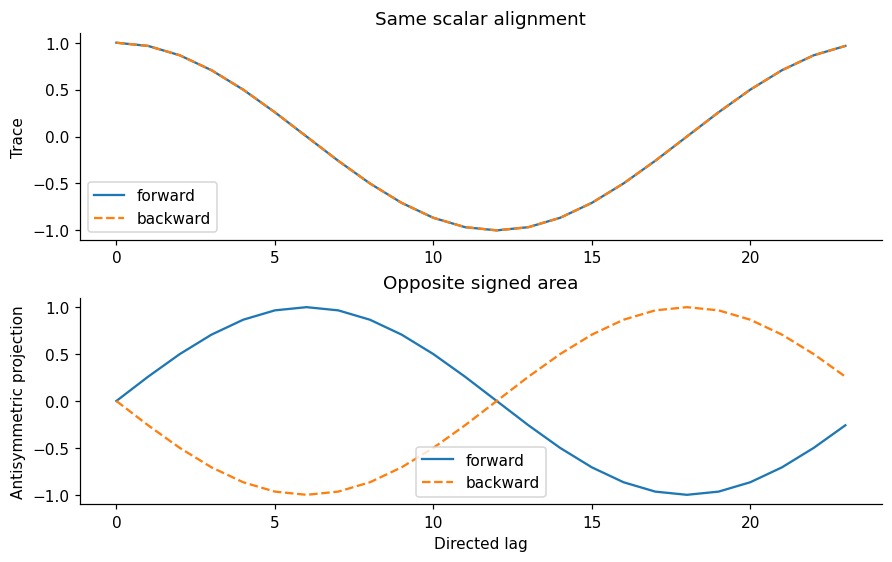

In [5]:
n=24
theta=2*np.pi*np.arange(n)/n
forward=np.column_stack([np.cos(theta),np.sin(theta)])
backward=forward*np.array([1,-1])
mf,mb=map(matrix_profile,[forward,backward])
trace=lambda m:np.trace(m,axis1=1,axis2=2)
antisymmetric=lambda m:m[:,0,1]-m[:,1,0]
np.testing.assert_allclose(trace(mf),trace(mb),atol=1e-12)
np.testing.assert_allclose(antisymmetric(mf),np.sin(theta),atol=1e-12)
np.testing.assert_allclose(antisymmetric(mb),-np.sin(theta),atol=1e-12)
fig,axes=plt.subplots(2,1,figsize=(8,5))
for m,name,ls in [(mf,'forward','-'),(mb,'backward','--')]:
    axes[0].plot(trace(m),ls,label=name)
    axes[1].plot(antisymmetric(m),ls,label=name)
axes[0].set(ylabel='Trace',title='Same scalar alignment')
axes[1].set(xlabel='Directed lag',ylabel='Antisymmetric projection',title='Opposite signed area')
for ax in axes:ax.legend()
show('13_trace_and_antisymmetry')

## Compare at equal scalar budgets
The trace and the antisymmetric projection each supply one real number per lag. At lag 6 the traces are both zero while the signed areas are +1 and −1. The full matrix provides four values per lag and retains both. If reflection or reversal is a nuisance, the two rotation senses can be treated as equivalent. This example treats rotation sense as a property of interest.

In [7]:
pd.DataFrame({'field':['forward','backward'],
              'trace at lag 6':[trace(mf)[6],trace(mb)[6]],
              'signed area at lag 6':[antisymmetric(mf)[6],antisymmetric(mb)[6]]}).round(8)

,field,trace at lag 6,signed area at lag 6
0,forward,-0.0,1.0
1,backward,-0.0,-1.0


This collision has a different cause from Notebook 12. Here a different projection of the same matrix suffices. For the two-state homometric pair, even the entire two-point matrix agrees, so changing its projection cannot help.